# Notebook 14 · Patent heterogeneity: clustering robustness + interactive patent explorer

**CNR–ISTAT / WIPO32 · 9 representations · reproducible Colab experiment**

### Our research question
> Does the WIPO-stratified patent sample exhibit **meaningful and robust technological heterogeneity**, or do the observed clusters depend on embedding model, patent office, and algorithm choices?

This notebook is **not a model-selection competition**. It keeps all eight embeddings generated by Mauro **plus our chunked MiniLM09 baseline**, and extends Notebook 13 on the **same 6,400-patent pilot**.

- **Expanded K-Means:** K = 4, 6, 8, 12, 16, 24, 32, with repeated seeds. Reuse existing K=8/16 checkpoints from Notebook 13.
- **Spherical K-Means:** angular/directional clustering, explicitly normalizing centroids after each update. [Dhillon & Modha (2001)](https://doi.org/10.1023/A:1007612920971).
- **HDBSCAN:** density-based analysis on PCA-reduced 50D representations, with parameter sensitivity and a noise category. [scikit-learn reference](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html).
- **Within-office semantic contrast:** does a patent resemble another patent from the **same WIPO selection field** more than a different field from the **same office group**?
- **Interactive UMAP + Plotly:** hover patent title and preview; **click a point to read the abstract** and open Google Patents. Color points by WIPO, office, K-Means, spherical K-Means or HDBSCAN.
- **30-minute optional examples:** a deterministic, *illustrative* (NOT statistically representative) 27-entry review sheet across all nine models.

**Scope:** the geometry and cluster labels are computed in the original high-dimensional spaces (or explicitly PCA-reduced for HDBSCAN). **UMAP is used only for visualization** and must never be interpreted as validation, a count of natural clusters, or a cross-model common coordinate system.

**Prerequisites:** Notebook 12 audit in Drive; Notebook 13 pilot complete with all nine models; Notebook 09 full-corpus MiniLM files accessible. Notebook 13b review export is optional for the 30-minute exercise.

## 1 · Install dependencies and connect Drive

In [ ]:
# Lightweight packages for downloading, saving, plotting and clustering.
# sklearn>=1.3 includes sklearn.cluster.HDBSCAN; pin a recent stable version in Colab.
%pip -q install "huggingface_hub>=0.25" "pyarrow>=15" "scikit-learn>=1.5" \
  "umap-learn>=0.5.7" "plotly>=5.20" "joblib>=1.3" "threadpoolctl>=3.1"

In [ ]:
import os, gc, json, time, hashlib, re, html, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown
from huggingface_hub import hf_hub_download
from sklearn.cluster import KMeans, HDBSCAN, kmeans_plusplus
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, adjusted_mutual_info_score,
                             silhouette_score, pairwise_distances)
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.io import write_html
import umap

# Colab: the Drive location is identical to Notebooks 09, 12, 13 and 13b.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/istat_patents')
except ImportError:
    ROOT = Path.cwd() / 'istat_patents'

print('Project folder:', ROOT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/istat_patents


## 2 · Configuration: all nine representations, pilot first

In [ ]:
# Exact Hugging Face repository commit: identical to Notebooks 12/13.
HF_REPO = 'istat-ai/wipo32-patent-embeddings'
HF_REVISION = 'e570ab0121c6dff0e61b05b64dd7ee21b98b78b7'
MODEL_NAMES = [
    'bge-m3', 'qwen3-embedding-4b', 'qwen3-embedding-0.6b',
    'embeddinggemma-300m', 'paecter', 'pat-specter',
    'sbert-adapt-ub', 'mpnet', 'minilm09_chunked',
]

# Reuse EXACTLY the same cohort as Notebook 13, not a newly drawn pilot.
SOURCE_MODE = 'pilot_200_per_field'
SOURCE_POPULATION = 'all_texts'
REFERENCE_SEED = 42
K_VALUES = [4, 6, 8, 12, 16, 24, 32]
KMEANS_SEEDS = [42, 43]    # Enough to begin; increase to [42,43,44] later.
KMEANS_N_INIT = 10         # Same as Notebook 13.

# Only 8, 16, 32 initially for spherical clustering; extend if informative.
SPHERICAL_K_VALUES = [8, 16, 32]
SPHERICAL_SEEDS = [42, 43]
SPHERICAL_N_INIT = 2
SPHERICAL_MAX_ITER = 65

# Density clustering on PCA50: an *exploratory* method with its own representation.
HDBSCAN_PCA_DIMS = 50
HDBSCAN_CONFIGS = [(75, 10), (150, 20)]  # (min_cluster_size, min_samples)

# Run switches. For a first diagnostic, you can set MAKE_INTERACTIVE=False.
RUN_KMEANS_GRID = True
RUN_SPHERICAL = True
RUN_HDBSCAN = True
RUN_WITHIN_OFFICE_CONTRAST = True
MAKE_INTERACTIVE = True
MAKE_30_MIN_REVIEW = True

THREADS = 4
VIZ_N_PATENTS = 2400    # Same sampled patent IDs in every model's interactive map.
VIZ_SEED = 20261116
UMAP_N_NEIGHBORS = 25
UMAP_MIN_DIST = 0.15
WITHIN_OFFICE_PAIRS = 1200

AUDIT_DIR = ROOT / 'semantic_results_v9_multimodel_audit'
MINILM_DIR = ROOT / 'semantic_results_v6_full_corpus'
SOURCE_DIR = (ROOT / 'semantic_results_v10_multimodel_kmeans'
              / SOURCE_MODE / SOURCE_POPULATION)
OUTPUT_DIR = (ROOT / 'semantic_results_v11_clustering_robustness'
              / SOURCE_MODE / SOURCE_POPULATION)
for part in ['labels','metrics','models','figures','interactive','projections']:
    (OUTPUT_DIR / part).mkdir(parents=True, exist_ok=True)
HF_CACHE_DIR = '/content/hf_patent_cache'
print('Input:', SOURCE_DIR)
print('Outputs:', OUTPUT_DIR)

Input: /content/drive/MyDrive/istat_patents/semantic_results_v10_multimodel_kmeans/pilot_200_per_field/all_texts
Outputs: /content/drive/MyDrive/istat_patents/semantic_results_v11_clustering_robustness/pilot_200_per_field/all_texts


## 3 · Alignment checks: never mix different patent orders

In [ ]:
# Read the precisely versioned audit and original pilot created by Notebook 13.
required = [AUDIT_DIR / '12_patents_master_index.parquet',
            AUDIT_DIR / '12_embedding_manifest.json',
            SOURCE_DIR / '13_cohort_master.parquet',
            SOURCE_DIR / '13_master_positions.npy',
            SOURCE_DIR / '13_silhouette_sample_positions.npy',
            SOURCE_DIR / 'experiment_config.json']
for file in required:
    if not file.exists():
        raise FileNotFoundError(f'Input missing: {file}. Run Notebooks 12 and 13 first.')

master = pd.read_parquet(required[0])
manifest = json.loads(required[1].read_text())
cohort = pd.read_parquet(required[2])
positions = np.load(required[3], allow_pickle=False)
sil_pos = np.load(required[4], allow_pickle=False)
source_config = json.loads(required[5].read_text())

for frame in (master, cohort):
    frame['publication_number'] = frame['publication_number'].astype('string')

def fingerprint(ids):
    """Hash *ordered* IDs, using the convention in Notebooks 12/13."""
    digest = hashlib.sha256()
    for item in ids:
        digest.update(str(item).encode('utf-8'))
        digest.update(b'\0')
    return digest.hexdigest()

assert manifest['dataset_revision'] == HF_REVISION == source_config['revision']
assert fingerprint(master.publication_number) == manifest['canonical_ids_order_sha256']
assert fingerprint(cohort.publication_number) == source_config['cohort_hash']
assert np.array_equal(master.publication_number.iloc[positions].to_numpy(),
                      cohort.publication_number.to_numpy())
assert len(cohort) == len(positions) == 6400
assert len(sil_pos) == len(np.unique(sil_pos))
assert np.max(sil_pos) < len(cohort)
assert set([8,16]).issubset(set(source_config['k_values']))
assert set(KMEANS_SEEDS).issubset(set(source_config['seeds']))

N = len(cohort)
NAMES = cohort.publication_number.astype(str).to_numpy()
FIELD = cohort.wipo_field_number.astype(str).to_numpy()
OFFICE = cohort.office.fillna('Unknown').astype(str).to_numpy()
OFFICE_GROUP = cohort.office_group.fillna('Other').astype(str).to_numpy()

audit_config = dict(repo=HF_REPO, revision=HF_REVISION,
                    cohort_hash=fingerprint(cohort.publication_number),
                    models=MODEL_NAMES, k_values=K_VALUES,
                    kmeans_seeds=KMEANS_SEEDS, kmeans_n_init=KMEANS_N_INIT,
                    spherical_k_values=SPHERICAL_K_VALUES,
                    spherical_seeds=SPHERICAL_SEEDS,
                    spherical_n_init=SPHERICAL_N_INIT,
                    hdbscan_pca_dims=HDBSCAN_PCA_DIMS,
                    hdbscan_configs=HDBSCAN_CONFIGS)
# JSON round-trip makes tuple/list representations identical on re-runs.
audit_config = json.loads(json.dumps(audit_config))
config_path = OUTPUT_DIR / '14_experiment_config.json'
if config_path.exists():
    old = json.loads(config_path.read_text())
    # Checkpoint-safe *extensions* of seeds/K/parameter grids are supported.
    expandable = ['k_values','kmeans_seeds','spherical_k_values',
                  'spherical_seeds','hdbscan_configs']
    changed_immutable = [key for key in audit_config
                         if key not in expandable and old.get(key)!=audit_config[key]]
    extensions_ok = all(
        set(map(str,old.get(key,[]))).issubset(set(map(str,audit_config[key])))
        for key in expandable)
    if changed_immutable or not extensions_ok:
        raise ValueError('Configuration conflicts with saved results. '
                         f'Immutable changes: {changed_immutable}. '
                         'Only ADD new K/seeds/HDBSCAN settings or use a new folder.')
    if old != audit_config:
        config_path.write_text(json.dumps(audit_config, indent=2))
        print('Safely extending existing settings without invalidating checkpoints.')
else:
    config_path.write_text(json.dumps(audit_config, indent=2))

print(f'All validation checks passed: {N:,} patents, {len(MODEL_NAMES)} models.')
print('Country/office concentration:', pd.Series(OFFICE).value_counts().head().to_dict())
print('Common silhouette sample:', len(sil_pos))

All validation checks passed: 6,400 patents, 9 models.
Country/office concentration: {'CN': 4330, 'US': 846, 'WO': 303, 'EP': 208, 'JP': 193}
Common silhouette sample: 1200


## 4 · Embedding loader: one matrix at a time, float32 and normalized

In [ ]:
# Model source vectors have different dimensions and float16 storage.
# Convert only selected patent rows to float32. Recheck every row's norm.
def hf_get(folder, name):
    return Path(hf_hub_download(repo_id=HF_REPO, repo_type='dataset',
                 revision=HF_REVISION, filename=f'{folder}/{name}',
                 cache_dir=HF_CACHE_DIR))

def load_embeddings(model):
    if model == 'minilm09_chunked':
        ids_file = MINILM_DIR / 'full_corpus_metadata.parquet'
        arr_file = MINILM_DIR / 'full_minilm_chunked_embeddings.npy'
        if not ids_file.is_file() or not arr_file.is_file():
            raise FileNotFoundError('Notebook 09 baseline missing in Drive.')
        original_ids = pd.read_parquet(ids_file, columns=['publication_number'])
        indexer = pd.Index(original_ids.publication_number.astype('string')).get_indexer(
            pd.Index(cohort.publication_number))
        if (indexer < 0).any():
            raise ValueError('MiniLM09 missing some cohort IDs.')
        raw = np.load(arr_file, mmap_mode='r', allow_pickle=False)
        X = np.asarray(raw[indexer], dtype=np.float32)
    else:
        ids = pd.read_parquet(hf_get(model, 'ids.parquet'), columns=['publication_number'])
        if fingerprint(ids.publication_number.astype('string')) != manifest['canonical_ids_order_sha256']:
            raise ValueError(f'{model}: publication ID order mismatch.')
        raw = np.load(hf_get(model, 'embeddings.npy'), mmap_mode='r', allow_pickle=False)
        if raw.ndim != 2 or len(raw) != len(master):
            raise ValueError(f'{model}: invalid embedding dimensions {raw.shape}.')
        X = np.asarray(raw[positions], dtype=np.float32)
    del raw
    if not np.isfinite(X).all():
        raise ValueError(f'{model}: nonfinite embeddings.')
    norms = np.linalg.norm(X, axis=1)
    if (norms < 1e-10).any():
        raise ValueError(f'{model}: zero embeddings.')
    X = normalize(X, axis=1, norm='l2', copy=False)
    return np.ascontiguousarray(X, dtype=np.float32)

# Reuse the *exact* evaluation IDs for every algorithm, K and model.
def fixed_cosine_distances(X):
    return pairwise_distances(X[sil_pos], metric='cosine', n_jobs=1).astype(np.float32)

## 5 · Algorithms: what changes and why?

**Standard K-Means:** approximately compact groups in Euclidean geometry (as in Notebook 13).

**Spherical K-Means:** documents are assigned by **highest cosine similarity to a unit-normalized centroid**; each centroid is the normalized mean of its cluster. This follows the document-clustering objective described by [Dhillon & Modha (2001)](https://doi.org/10.1023/A:1007612920971). We run multiple initializations and record stability rather than assuming spherical is always better.

**HDBSCAN:** no predefined K; it allows noise (`-1`) and detects density-connected groups. Here we fit it **on PCA50**, not on the high-dimensional original vectors, because high-dimensional density estimation can be unreliable and computationally demanding. PCA can change distances and must be explicitly reported. We test two settings rather than presenting one arbitrary output as truth.

**Important:** HDBSCAN cosine silhouette on the **assigned-only** subset cannot be directly compared with the full-cohort K-Means silhouette. Always interpret it alongside `coverage`, `noise_share`, and the number of discovered clusters.

In [ ]:
# Custom spherical K-Means implementation with multiple k-means++ initializations.
# Unlike ordinary K-Means, centroids are L2-normalized after every update.
def spherical_kmeans(X, k, seed, n_init=2, max_iter=65):
    """Return labels, normalized centroids, objective, iterations, for unit input X."""
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape
    best = None
    for init in range(n_init):
        centers, _ = kmeans_plusplus(X, n_clusters=k,
                                     random_state=int(seed)*1000+init)
        centers = normalize(centers.astype(np.float32), axis=1)
        last = None
        for it in range(max_iter):
            with threadpool_limits(limits=THREADS):
                cosine_scores = X @ centers.T
            labels = cosine_scores.argmax(axis=1).astype(np.int32)
            if last is not None and np.array_equal(labels, last):
                break
            last = labels.copy()
            new_centers = np.zeros((k, d), dtype=np.float32)
            # Use cluster means; no sparse/high-dimensional assumptions.
            for j in range(k):
                members = (labels == j)
                if members.any():
                    new_centers[j] = X[members].mean(axis=0)
                else:
                    # Empty group: re-seed from a poorly represented observation.
                    worst = np.argmin(cosine_scores.max(axis=1))
                    new_centers[j] = X[worst]
            centers = normalize(new_centers, axis=1)
        with threadpool_limits(limits=THREADS):
            scores = X @ centers.T
        labels = scores.argmax(axis=1).astype(np.int32)
        objective = float(scores[np.arange(n), labels].mean())
        if best is None or objective > best[2]:
            best = (labels.copy(), centers.copy(), objective, it + 1)
    return best

# Separate code check: a toy dataset must yield finite, unit-norm centroids.
_rng = np.random.default_rng(123)
_toy = normalize(_rng.normal(size=(240, 16)).astype('float32'))
_toy_labels, _toy_centers, _toy_obj, _toy_iter = spherical_kmeans(
    _toy, k=5, seed=42, n_init=2, max_iter=20)
assert _toy_labels.shape == (240,)
assert np.all(np.isfinite(_toy_centers))
assert np.allclose(np.linalg.norm(_toy_centers, axis=1), 1, atol=1e-5)
print('Spherical K-Means smoke test passed.')

Spherical K-Means smoke test passed.


## 6 · Metrics and durable checkpoints

In [ ]:
# Labels and measured scores are saved separately for each model, algorithm and setting.
# Existing results are loaded when the notebook is re-run; no need to refit them.
def tag(model, algorithm, k=None, seed=None, suffix=''):
    parts = [model, algorithm]
    if k is not None: parts.append(f'k{k}')
    if seed is not None: parts.append(f'seed{seed}')
    if suffix: parts.append(suffix)
    return '__'.join(parts)

def saved_label_path(key):
    return OUTPUT_DIR / 'labels' / f'{key}.npy'

def saved_metric_path(key):
    return OUTPUT_DIR / 'metrics' / f'{key}.json'

def save_run(key, labels, metrics):
    # Avoid a partially written label file if Colab disconnects.
    tmp = saved_label_path(key).with_suffix('.tmp.npy')
    np.save(tmp, labels.astype(np.int32))
    os.replace(tmp, saved_label_path(key))
    saved_metric_path(key).write_text(json.dumps(metrics, indent=2))

def score_run(X, labels, D, *, model, method, setting, k_requested=None,
              seed=None, seconds=None, cached=False):
    labels = np.asarray(labels, dtype=np.int32)
    assigned = labels >= 0
    assigned_labels = labels[assigned]
    actual_k = len(np.unique(assigned_labels))
    coverage = float(assigned.mean())
    counts = pd.Series(assigned_labels).value_counts(normalize=True)
    H = float(-(counts*np.log(counts)).sum()) if len(counts) else np.nan

    # Evaluation cohort is the SAME patent IDs for all configurations.
    s_labels = labels[sil_pos]
    s_good = s_labels >= 0
    # Cosine silhouette on the whole cohort only if *all* observations are assigned.
    sil_all = np.nan
    if assigned.all() and 2 <= len(np.unique(s_labels)) < len(s_labels):
        sil_all = float(silhouette_score(D, s_labels, metric='precomputed'))
    # For HDBSCAN only, this silhouette excludes noise and is NOT directly comparable.
    sil_assigned = np.nan
    s_clustered = s_labels[s_good]
    if method == 'HDBSCAN' and len(s_clustered) >= 10 and 2 <= len(np.unique(s_clustered)) < len(s_clustered):
        sil_assigned = float(silhouette_score(
            D[np.ix_(s_good, s_good)], s_clustered, metric='precomputed'))

    # NOTE: WIPO field is a deterministic reference for a multi-field patent system.
    # HDBSCAN assigned-only AMI is evaluated on a selected subset and must be qualified.
    wipo_all = float(adjusted_mutual_info_score(FIELD, labels)) if actual_k >= 2 else np.nan
    office_all = float(adjusted_mutual_info_score(OFFICE_GROUP, labels)) if actual_k >= 2 else np.nan
    wipo_assigned = (float(adjusted_mutual_info_score(FIELD[assigned], labels[assigned]))
                     if 2 <= actual_k < assigned.sum() else np.nan)
    return dict(model=model, method=method, setting=setting,
                k_requested=k_requested, k_found=int(actual_k), seed=seed,
                n_patents=int(N), coverage=coverage, noise_share=1-coverage,
                silhouette_cosine_all=sil_all,
                silhouette_cosine_assigned_only=sil_assigned,
                AMI_WIPO_all=wipo_all, AMI_office_all=office_all,
                AMI_WIPO_assigned_only=wipo_assigned,
                effective_cluster_count=float(np.exp(H)) if np.isfinite(H) else np.nan,
                largest_cluster_share_assigned=float(counts.max()) if len(counts) else np.nan,
                seconds=seconds, checkpoint_reused=bool(cached))

def get_or_fit_kmeans(model, X, D, k, seed):
    key = tag(model, 'kmeans', k, seed)
    if saved_label_path(key).exists() and saved_metric_path(key).exists():
        return np.load(saved_label_path(key)), json.loads(saved_metric_path(key).read_text())

    # The K=8/16 checkpoints from Notebook 13 already exist: reuse them.
    prior = SOURCE_DIR / 'labels' / f'{model}__k{k}__seed{seed}.npy'
    if prior.exists():
        labels = np.load(prior, allow_pickle=False)
        reused = True
        seconds = 0.0
    else:
        started = time.perf_counter()
        with threadpool_limits(limits=THREADS):
            km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT,
                        random_state=seed, max_iter=300)
            labels = km.fit_predict(X)
        seconds = time.perf_counter()-started
        joblib.dump(km, OUTPUT_DIR/'models'/f'{key}.joblib')
        reused = False
    if len(labels) != N:
        raise ValueError(f'{key}: number of labels does not match cohort.')
    metrics = score_run(X, labels, D, model=model, method='KMeans',
                        setting=f'k{k}', k_requested=k, seed=seed,
                        seconds=seconds, cached=reused)
    save_run(key, labels, metrics)
    return labels, metrics

def get_or_fit_spherical(model, X, D, k, seed):
    key = tag(model, 'spherical', k, seed)
    if saved_label_path(key).exists() and saved_metric_path(key).exists():
        return np.load(saved_label_path(key)), json.loads(saved_metric_path(key).read_text())
    started = time.perf_counter()
    labels, centers, obj, iters = spherical_kmeans(
        X, k, seed, n_init=SPHERICAL_N_INIT, max_iter=SPHERICAL_MAX_ITER)
    seconds = time.perf_counter() - started
    np.save(OUTPUT_DIR/'models'/f'{key}__centroids.npy', centers)
    metrics = score_run(X, labels, D, model=model, method='Spherical',
                        setting=f'k{k}', k_requested=k, seed=seed, seconds=seconds)
    metrics.update(spherical_cosine_objective=obj, spherical_iterations=iters)
    save_run(key, labels, metrics)
    return labels, metrics

def get_or_fit_hdbscan(model, X50, D, mcs, ms):
    key = tag(model, 'hdbscan', suffix=f'pca{HDBSCAN_PCA_DIMS}__mcs{mcs}__ms{ms}')
    if saved_label_path(key).exists() and saved_metric_path(key).exists():
        return np.load(saved_label_path(key)), json.loads(saved_metric_path(key).read_text())
    started = time.perf_counter()
    with threadpool_limits(limits=THREADS):
        clusterer = HDBSCAN(min_cluster_size=mcs, min_samples=ms,
                            metric='euclidean', cluster_selection_method='eom',
                            n_jobs=THREADS)
        labels = clusterer.fit_predict(X50)
    seconds = time.perf_counter() - started
    # The density analysis is on the PCA representation, with the original
    # high-dimensional cosine D used only for additional descriptive silhouette.
    metrics = score_run(None, labels, D, model=model, method='HDBSCAN',
                        setting=f'PCA{HDBSCAN_PCA_DIMS}_mcs{mcs}_ms{ms}',
                        seconds=seconds)
    save_run(key, labels, metrics)
    return labels, metrics

## 7 · Within-office WIPO similarity contrast (extra evidence for heterogeneity)

For a random eligible **anchor** patent, select (A) another patent from the **same office group and the same WIPO selection field**, and (B) one from the **same office group but a different WIPO field**. Compare the cosine similarities `sim(anchor,A) − sim(anchor,B)`.

A positive mean suggests that technological-field information is present **even within an office group**, reducing one obvious source of confounding. This does **not** independently prove semantic coherence: WIPO labels are imperfect, often multiple, and these are not independently sampled patent pairs. Report the distribution alongside the mean, not a p-value.

In [ ]:
def matched_office_pair_positions(n_pairs=1200, seed=42):
    rng = np.random.default_rng(seed)
    group_map = {}
    office_map = {}
    for i in range(N):
        group_map.setdefault((OFFICE_GROUP[i], FIELD[i]), []).append(i)
        office_map.setdefault(OFFICE_GROUP[i], []).append(i)
    # Select eligible anchors once; same pairs reused across all nine models.
    eligible = []
    for i in range(N):
        same = group_map[(OFFICE_GROUP[i], FIELD[i])]
        diff = [j for j in office_map[OFFICE_GROUP[i]] if FIELD[j] != FIELD[i]]
        if len(same) > 1 and len(diff) > 0:
            eligible.append(i)
    anchors = rng.choice(eligible, size=min(n_pairs,len(eligible)), replace=False)
    same_field, different_field = [], []
    for i in anchors:
        same_candidates = [j for j in group_map[(OFFICE_GROUP[i], FIELD[i])] if j != i]
        # Avoid reconstructing all 'different field' candidates for every anchor.
        j = int(rng.choice(same_candidates))
        other = office_map[OFFICE_GROUP[i]]
        while True:
            z = int(rng.choice(other))
            if FIELD[z] != FIELD[i]: break
        same_field.append(j)
        different_field.append(z)
    return (np.asarray(anchors), np.asarray(same_field),
            np.asarray(different_field))

PAIR_A, PAIR_SAME, PAIR_DIFF = matched_office_pair_positions(WITHIN_OFFICE_PAIRS, seed=42)
print('Matched anchors:', len(PAIR_A))

def pair_contrast(X, model):
    cosine_same = np.einsum('ij,ij->i', X[PAIR_A], X[PAIR_SAME])
    cosine_different = np.einsum('ij,ij->i', X[PAIR_A], X[PAIR_DIFF])
    delta = cosine_same - cosine_different
    # Bootstrap here is only a descriptive interval: paired anchors are not fully independent.
    rng = np.random.default_rng(123)
    bootstrap = [float(rng.choice(delta, size=len(delta), replace=True).mean())
                 for _ in range(300)]
    row = dict(model=model, n_pairs=len(delta), mean_same=float(cosine_same.mean()),
               mean_diff=float(cosine_different.mean()),
               mean_paired_difference=float(delta.mean()),
               fraction_positive=float((delta>0).mean()),
               descriptive_bootstrap_low=float(np.percentile(bootstrap, 2.5)),
               descriptive_bootstrap_high=float(np.percentile(bootstrap, 97.5)))
    return row

Matched anchors: 1200


## 8 · Run the complete pilot: all nine models, checkpoints after each fit

In [ ]:
# You can interrupt this cell and rerun it: finished combinations are recovered.
# All nine representations are retained. Each is loaded once in this loop.
all_pair_rows = []
for ii, model in enumerate(MODEL_NAMES, start=1):
    print(f'\n==== [{ii}/{len(MODEL_NAMES)}] {model} ====')
    started_model = time.perf_counter()
    X = load_embeddings(model)
    D = fixed_cosine_distances(X)
    print('Embeddings', X.shape, '| cosine sample', D.shape)

    if RUN_WITHIN_OFFICE_CONTRAST:
        pair_row = pair_contrast(X, model)
        all_pair_rows.append(pair_row)
        pd.DataFrame(all_pair_rows).to_csv(
            OUTPUT_DIR/'14_within_office_pair_contrast_progress.csv', index=False)
        print('Within-office paired cosine gap:',
              round(pair_row['mean_paired_difference'], 4))

    if RUN_KMEANS_GRID:
        for k in K_VALUES:
            for seed in KMEANS_SEEDS:
                labels, metrics = get_or_fit_kmeans(model, X, D, k, seed)
                print(f'  KMeans K={k:2d}, seed={seed}: '
                      f'AMI={metrics["AMI_WIPO_all"]:.3f}, '
                      f'silhouette={metrics["silhouette_cosine_all"]:.3f} '
                      f'{"[cached]" if metrics["checkpoint_reused"] else ""}')
    if RUN_SPHERICAL:
        for k in SPHERICAL_K_VALUES:
            for seed in SPHERICAL_SEEDS:
                labels, metrics = get_or_fit_spherical(model, X, D, k, seed)
                print(f'  Spherical K={k:2d}, seed={seed}: '
                      f'AMI={metrics["AMI_WIPO_all"]:.3f}, '
                      f'silhouette={metrics["silhouette_cosine_all"]:.3f}')

    if RUN_HDBSCAN:
        # PCA is fitted separately for each model (no labels involved).
        # The PCA representation is used exclusively for this density experiment.
        max_comp = min(HDBSCAN_PCA_DIMS, X.shape[1]-1, N-1)
        with threadpool_limits(limits=THREADS):
            pca = PCA(n_components=max_comp, svd_solver='randomized', random_state=42)
            X50 = pca.fit_transform(X).astype('float32')
        print(f'  PCA{max_comp}: retained variance '
              f'{pca.explained_variance_ratio_.sum():.1%}')
        for mcs, ms in HDBSCAN_CONFIGS:
            labels, metrics = get_or_fit_hdbscan(model, X50, D, mcs, ms)
            print(f'  HDBSCAN mcs={mcs:3d}, ms={ms:2d}: '
                  f'clusters={metrics["k_found"]}, coverage={metrics["coverage"]:.1%}')
        del X50, pca

    print('Model completed; elapsed for this pass:',
          round(time.perf_counter()-started_model, 1), 's')
    del X, D
    gc.collect()

if all_pair_rows:
    pd.DataFrame(all_pair_rows).to_csv(OUTPUT_DIR/'14_within_office_pair_contrast.csv', index=False)
print('Computations completed; run the next cells to summarize.')


==== [1/9] bge-m3 ====


bge-m3/ids.parquet: reconstructing file:   0%|          |  0.00B /  549kB            

bge-m3/ids.parquet: downloading bytes:           |  0.00B            

bge-m3/embeddings.npy: reconstructing file:   0%|          |  0.00B /  131MB            

bge-m3/embeddings.npy: downloading bytes:           |  0.00B            

Embeddings (6400, 1024) | cosine sample (1200, 1200)
Within-office paired cosine gap: 0.0544
  KMeans K= 4, seed=42: AMI=0.208, silhouette=0.061 
  KMeans K= 4, seed=43: AMI=0.208, silhouette=0.061 
  KMeans K= 6, seed=42: AMI=0.265, silhouette=0.064 
  KMeans K= 6, seed=43: AMI=0.265, silhouette=0.064 
  KMeans K= 8, seed=42: AMI=0.266, silhouette=0.052 [cached]
  KMeans K= 8, seed=43: AMI=0.266, silhouette=0.044 [cached]
  KMeans K=12, seed=42: AMI=0.283, silhouette=0.039 
  KMeans K=12, seed=43: AMI=0.288, silhouette=0.041 
  KMeans K=16, seed=42: AMI=0.301, silhouette=0.038 [cached]
  KMeans K=16, seed=43: AMI=0.299, silhouette=0.038 [cached]
  KMeans K=24, seed=42: AMI=0.315, silhouette=0.037 
  KMeans K=24, seed=43: AMI=0.311, silhouette=0.033 
  KMeans K=32, seed=42: AMI=0.318, silhouette=0.026 
  KMeans K=32, seed=43: AMI=0.320, silhouette=0.027 
  Spherical K= 8, seed=42: AMI=0.276, silhouette=0.054
  Spherical K= 8, seed=43: AMI=0.271, silhouette=0.055
  Spherical K=16, seed=

... (17 outputs left out)

Embeddings (6400, 384) | cosine sample (1200, 1200)
Within-office paired cosine gap: 0.3492
  KMeans K= 4, seed=42: AMI=0.274, silhouette=0.268 
  KMeans K= 4, seed=43: AMI=0.274, silhouette=0.268 
  KMeans K= 6, seed=42: AMI=0.304, silhouette=0.259 
  KMeans K= 6, seed=43: AMI=0.305, silhouette=0.259 
  KMeans K= 8, seed=42: AMI=0.325, silhouette=0.257 [cached]
  KMeans K= 8, seed=43: AMI=0.326, silhouette=0.258 [cached]
  KMeans K=12, seed=42: AMI=0.344, silhouette=0.257 
  KMeans K=12, seed=43: AMI=0.346, silhouette=0.259 
  KMeans K=16, seed=42: AMI=0.350, silhouette=0.227 [cached]
  KMeans K=16, seed=43: AMI=0.355, silhouette=0.233 [cached]
  KMeans K=24, seed=42: AMI=0.365, silhouette=0.204 
  KMeans K=24, seed=43: AMI=0.367, silhouette=0.207 
  KMeans K=32, seed=42: AMI=0.374, silhouette=0.196 
  KMeans K=32, seed=43: AMI=0.364, silhouette=0.204 
  Spherical K= 8, seed=42: AMI=0.323, silhouette=0.258
  Spherical K= 8, seed=43: AMI=0.321, silhouette=0.273
  Spherical K=16, seed=4

mpnet/embeddings.npy: reconstructing file:   0%|          |  0.00B / 98.3MB            

mpnet/embeddings.npy: downloading bytes:           |  0.00B            

Embeddings (6400, 768) | cosine sample (1200, 1200)
Within-office paired cosine gap: 0.0939
  KMeans K= 4, seed=42: AMI=0.262, silhouette=0.068 
  KMeans K= 4, seed=43: AMI=0.262, silhouette=0.068 
  KMeans K= 6, seed=42: AMI=0.276, silhouette=0.056 
  KMeans K= 6, seed=43: AMI=0.282, silhouette=0.057 
  KMeans K= 8, seed=42: AMI=0.300, silhouette=0.054 [cached]
  KMeans K= 8, seed=43: AMI=0.295, silhouette=0.060 [cached]
  KMeans K=12, seed=42: AMI=0.307, silhouette=0.053 
  KMeans K=12, seed=43: AMI=0.307, silhouette=0.057 
  KMeans K=16, seed=42: AMI=0.329, silhouette=0.056 [cached]
  KMeans K=16, seed=43: AMI=0.318, silhouette=0.056 [cached]
  KMeans K=24, seed=42: AMI=0.340, silhouette=0.051 
  KMeans K=24, seed=43: AMI=0.340, silhouette=0.048 
  KMeans K=32, seed=42: AMI=0.354, silhouette=0.052 
  KMeans K=32, seed=43: AMI=0.356, silhouette=0.054 
  Spherical K= 8, seed=42: AMI=0.303, silhouette=0.056
  Spherical K= 8, seed=43: AMI=0.278, silhouette=0.053
  Spherical K=16, seed=4

## 9 · Aggregate measured results and stability across seeds

In [ ]:
# Read all saved JSON metrics: no need to recompute fitted clusters for reports.
rows = [json.loads(p.read_text()) for p in sorted((OUTPUT_DIR/'metrics').glob('*.json'))]
metrics = pd.DataFrame(rows)
if metrics.empty:
    raise RuntimeError('No clustering metrics found. Run the previous cell first.')
metrics.to_csv(OUTPUT_DIR/'14_all_seed_metrics.csv', index=False)

# Stability: compare partitions on EXACTLY the same observations and same method.
stability_rows = []
for (model, method, setting), frame in metrics.groupby(['model','method','setting']):
    seeds = [int(s) for s in frame.seed.dropna().tolist()]
    if len(seeds) < 2: continue
    for a,b in itertools.combinations(sorted(set(seeds)),2):
        k = int(frame.k_requested.dropna().iloc[0])
        kind = 'kmeans' if method=='KMeans' else 'spherical'
        label_a = np.load(saved_label_path(tag(model,kind,k,a)),allow_pickle=False)
        label_b = np.load(saved_label_path(tag(model,kind,k,b)),allow_pickle=False)
        stability_rows.append(dict(model=model, method=method, setting=setting,
                                   seed_a=a,seed_b=b,
                                   ARI=float(adjusted_rand_score(label_a,label_b))))
stability = pd.DataFrame(stability_rows)
stability.to_csv(OUTPUT_DIR/'14_seed_stability_ARI.csv', index=False)

# Direct comparison of clustering *algorithms* on the same model and patent IDs.
# For HDBSCAN we report ARI both with noise treated as a label and on its
# assigned subset; an assigned-only score has conditional/sample-selection meaning.
cross_method_rows = []
for model in MODEL_NAMES:
    for k in sorted(set(K_VALUES).intersection(SPHERICAL_K_VALUES)):
        standard_file = saved_label_path(tag(model,'kmeans',k,REFERENCE_SEED))
        spherical_file = saved_label_path(tag(model,'spherical',k,REFERENCE_SEED))
        if standard_file.exists() and spherical_file.exists():
            a=np.load(standard_file,allow_pickle=False)
            b=np.load(spherical_file,allow_pickle=False)
            cross_method_rows.append(dict(model=model,comparison='KMeans vs Spherical',
                setting=f'k{k}',n_compared=len(a),
                coverage=1.,ARI=float(adjusted_rand_score(a,b))))
    std_file=saved_label_path(tag(model,'kmeans',8,REFERENCE_SEED))
    if not std_file.exists(): continue
    a=np.load(std_file,allow_pickle=False)
    for mcs,ms in HDBSCAN_CONFIGS:
        hkey=tag(model,'hdbscan',suffix=f'pca{HDBSCAN_PCA_DIMS}__mcs{mcs}__ms{ms}')
        f=saved_label_path(hkey)
        if not f.exists(): continue
        b=np.load(f,allow_pickle=False)
        good=b>=0
        cross_method_rows.append(dict(model=model,comparison='KMeans K8 vs HDBSCAN',
            setting=f'mcs{mcs}_ms{ms}, all incl. noise',n_compared=N,
            coverage=float(good.mean()),ARI=float(adjusted_rand_score(a,b))))
        if good.sum()>=2 and len(np.unique(b[good]))>=2:
            cross_method_rows.append(dict(model=model,
                comparison='KMeans K8 vs HDBSCAN, assigned only',
                setting=f'mcs{mcs}_ms{ms}',n_compared=int(good.sum()),
                coverage=float(good.mean()),
                ARI=float(adjusted_rand_score(a[good],b[good]))))
pd.DataFrame(cross_method_rows).to_csv(OUTPUT_DIR/'14_cross_method_ARI.csv',index=False)

summary = (metrics.groupby(['model','method','setting'],as_index=False)
    .agg(k_requested=('k_requested','first'),k_found=('k_found','mean'),
         repeats=('setting','size'),
         silhouette_cosine=('silhouette_cosine_all','mean'),
         silhouette_assigned_only=('silhouette_cosine_assigned_only','mean'),
         WIPO_AMI=('AMI_WIPO_all','mean'),office_AMI=('AMI_office_all','mean'),
         coverage=('coverage','mean'),noise_share=('noise_share','mean'),
         effective_cluster_count=('effective_cluster_count','mean'),
         largest_cluster_share=('largest_cluster_share_assigned','mean')))
if not stability.empty:
    stab_mean = (stability.groupby(['model','method','setting'],as_index=False)
                 .ARI.mean().rename(columns={'ARI':'seed_stability_ARI'}))
    summary = summary.merge(stab_mean, on=['model','method','setting'], how='left')
summary.to_csv(OUTPUT_DIR/'14_method_comparison_summary.csv', index=False)
print('Completed method settings:',len(summary))
display(summary.sort_values(['model','method','k_requested']).round(4).head(30))

Completed method settings: 108


,model,method,setting,k_requested,k_found,repeats,silhouette_cosine,silhouette_assigned_only,WIPO_AMI,office_AMI,coverage,noise_share,effective_cluster_count,largest_cluster_share,seed_stability_ARI
0,bge-m3,HDBSCAN,PCA50_mcs150_ms20,NaN,3.0,1,NaN,0.1990,0.0611,0.0370,0.1267,0.8733,2.7101,0.5487,NaN
1,bge-m3,HDBSCAN,PCA50_mcs75_ms10,NaN,3.0,1,NaN,0.1831,0.0711,0.0416,0.1730,0.8270,2.7053,0.5501,NaN
6,bge-m3,KMeans,k4,4.0,4.0,2,0.0610,NaN,0.2079,0.0851,1.0000,0.0000,3.9774,0.2926,0.9890
7,bge-m3,KMeans,k6,6.0,6.0,2,0.0637,NaN,0.2649,0.0847,1.0000,0.0000,5.7990,0.2138,0.9973
8,bge-m3,KMeans,k8,8.0,8.0,2,0.0482,NaN,0.2661,0.0739,1.0000,0.0000,7.7532,0.1893,0.8112
2,bge-m3,KMeans,k12,12.0,12.0,2,0.0402,NaN,0.2853,0.0810,1.0000,0.0000,11.6619,0.1154,0.8367
3,bge-m3,KMeans,k16,16.0,16.0,2,0.0384,NaN,0.3001,0.0752,1.0000,0.0000,15.3530,0.1095,0.7227
4,bge-m3,KMeans,k24,24.0,24.0,2,0.0348,NaN,0.3132,0.0740,1.0000,0.0000,22.9730,0.0762,0.5535
5,bge-m3,KMeans,k32,32.0,32.0,2,0.0265,NaN,0.3187,0.0724,1.0000,0.0000,30.9403,0.0495,0.5166
11,bge-m3,Spherical,k8,8.0,8.0,2,0.0542,NaN,0.2734,0.0779,1.0000,0.0000,7.6752,0.1895,0.7620


## 10 · Plots: K selection, spherical differences, HDBSCAN coverage

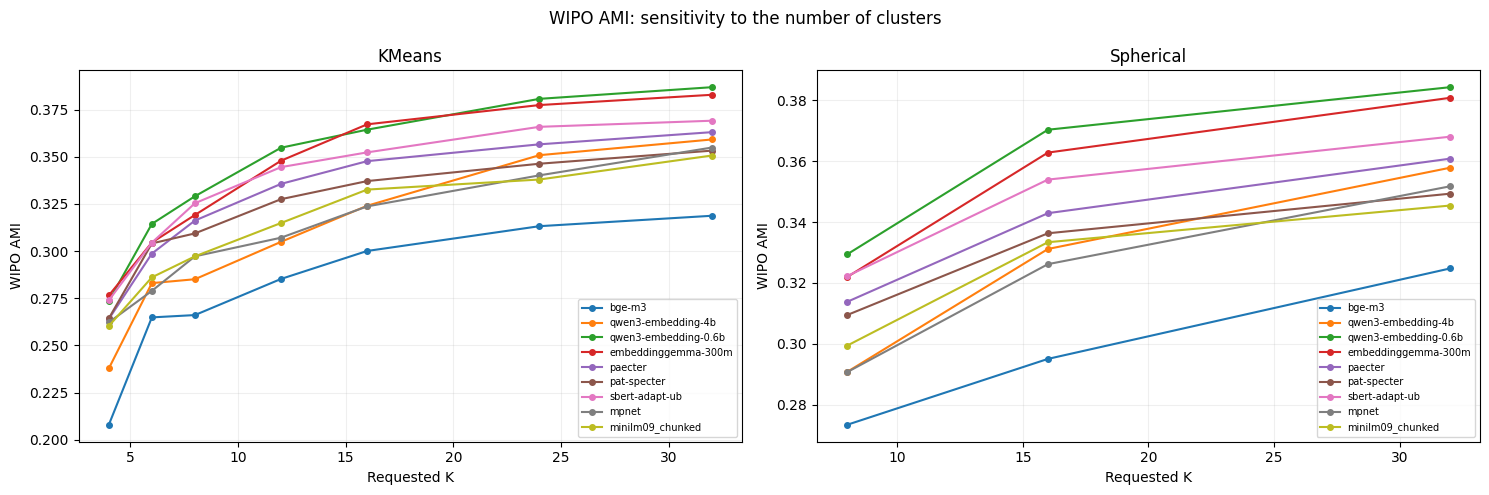

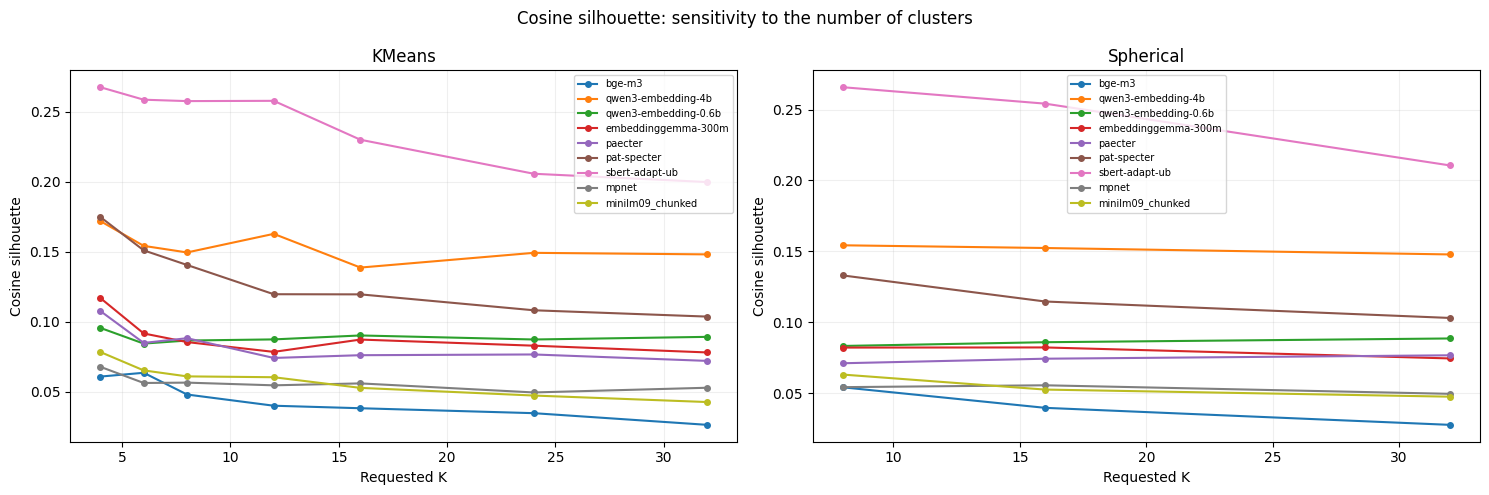

HDBSCAN: monitor *coverage and number of groups*, not silhouette alone.


,model,setting,k_found,coverage,WIPO_AMI,silhouette_assigned_only
0,bge-m3,PCA50_mcs150_ms20,3.0,0.127,0.061,0.199
1,bge-m3,PCA50_mcs75_ms10,3.0,0.173,0.071,0.183
12,embeddinggemma-300m,PCA50_mcs150_ms20,0.0,0.000,NaN,NaN
13,embeddinggemma-300m,PCA50_mcs75_ms10,2.0,0.111,0.053,0.257
24,minilm09_chunked,PCA50_mcs150_ms20,2.0,0.138,0.078,0.155
25,minilm09_chunked,PCA50_mcs75_ms10,2.0,0.122,0.073,0.161
36,mpnet,PCA50_mcs150_ms20,0.0,0.000,NaN,NaN
37,mpnet,PCA50_mcs75_ms10,2.0,0.056,0.058,0.166
48,paecter,PCA50_mcs150_ms20,3.0,0.218,0.095,0.304
49,paecter,PCA50_mcs75_ms10,5.0,0.236,0.120,0.278


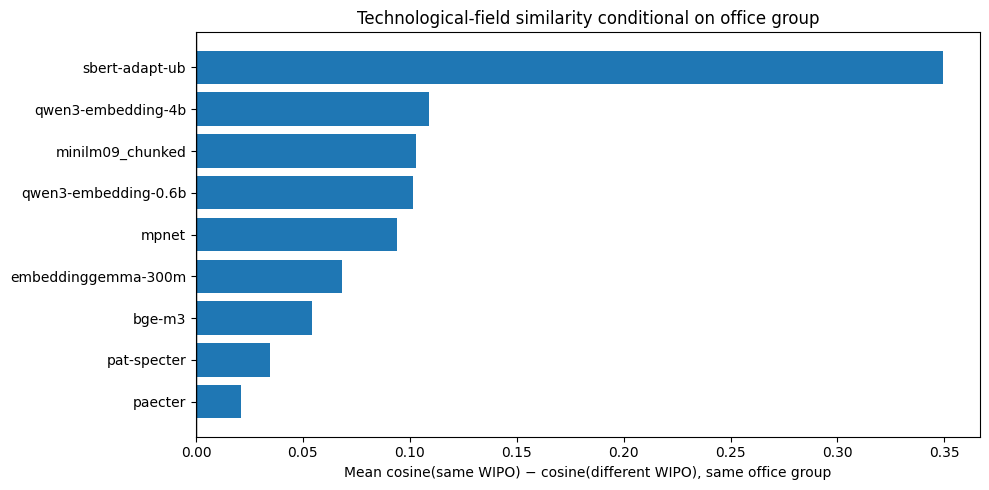

,model,n_pairs,mean_same,mean_diff,mean_paired_difference,fraction_positive,descriptive_bootstrap_low,descriptive_bootstrap_high
4,paecter,1200,0.8994,0.8783,0.0211,0.7783,0.0195,0.0226
5,pat-specter,1200,0.8929,0.8581,0.0348,0.7867,0.0326,0.0369
0,bge-m3,1200,0.5376,0.4832,0.0544,0.7400,0.0493,0.0594
3,embeddinggemma-300m,1200,0.7375,0.6692,0.0684,0.7842,0.0638,0.0723
7,mpnet,1200,0.3067,0.2128,0.0939,0.7725,0.0873,0.1023
2,qwen3-embedding-0.6b,1200,0.5054,0.4040,0.1014,0.7883,0.0944,0.1079
8,minilm09_chunked,1200,0.2570,0.1540,0.1030,0.7542,0.0954,0.1113
1,qwen3-embedding-4b,1200,0.6852,0.5762,0.1091,0.7783,0.1017,0.1166
6,sbert-adapt-ub,1200,0.4038,0.0546,0.3492,0.7967,0.3270,0.3708


In [ ]:
# Important: WIPO AMI may rise with K; higher K is not automatically better.
# Use multiple metrics and avoid one universal ranking across embedding geometries.
for outcome, ylabel in [('WIPO_AMI','WIPO AMI'),
                       ('silhouette_cosine','Cosine silhouette')]:
    fig, axes = plt.subplots(1,2,figsize=(15,5),sharey=False)
    for ax, method in zip(axes,['KMeans','Spherical']):
        frame = summary.loc[summary.method==method]
        for model in MODEL_NAMES:
            sub = frame[frame.model==model].sort_values('k_requested')
            if len(sub):
                ax.plot(sub.k_requested,sub[outcome],marker='o',ms=4,label=model)
        ax.set_title(method)
        ax.set_xlabel('Requested K')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=.2)
        ax.legend(fontsize=7,loc='best')
    fig.suptitle(f'{ylabel}: sensitivity to the number of clusters')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'figures'/f'14_{outcome}_by_K.png',dpi=170)
    plt.show()

hdb = summary[summary.method=='HDBSCAN'].copy()
if not hdb.empty:
    print('HDBSCAN: monitor *coverage and number of groups*, not silhouette alone.')
    display(hdb[['model','setting','k_found','coverage','WIPO_AMI',
                 'silhouette_assigned_only']].round(3))

# Pairwise similarity conditional on patent-office group.
pair_csv = OUTPUT_DIR/'14_within_office_pair_contrast.csv'
if pair_csv.exists():
    pairs = pd.read_csv(pair_csv).sort_values('mean_paired_difference')
    fig, ax = plt.subplots(figsize=(10,5))
    ax.barh(pairs.model, pairs.mean_paired_difference)
    ax.axvline(0,color='black',lw=1)
    ax.set_xlabel('Mean cosine(same WIPO) − cosine(different WIPO), same office group')
    ax.set_title('Technological-field similarity conditional on office group')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'figures'/'14_within_office_pair_contrast.png',dpi=180)
    plt.show()
    display(pairs.round(4))

## 11 · Interactive patent maps: hover + click

We compute a **separate UMAP projection for each model** on the same 2,400 patents. The map is a *visual explanation*, not a clustering input or validation statistic. Each model's axes are arbitrary and **not aligned** to another model's axes.

In each HTML map you can:
1. **Hover** on any dot to see patent ID, title, WIPO field, office and a brief abstract preview.
2. **Click** on a dot to open a panel with the full abstract and an external **Google Patents** link.
3. Use the dropdown to color the **same dots** by WIPO, office, K-Means K8/K16, spherical K8, or HDBSCAN. This is the easiest way to explain how algorithms assign **identical observations** differently.
4. Zoom, pan, search visually and save screenshots for Mauro.

The HTML uses Plotly from a CDN, so an internet connection is needed when viewing the saved file. The actual patent texts are embedded into the HTML file. Do not publish these HTML files without checking data usage conditions and the suitability of the included text.

In [ ]:
# Once chosen, visualization positions NEVER change across models.
viz_file = OUTPUT_DIR/'14_viz_positions.npy'
if viz_file.exists():
    viz_pos = np.load(viz_file,allow_pickle=False)
else:
    viz_pos = np.sort(np.random.default_rng(VIZ_SEED).choice(
        N,size=min(VIZ_N_PATENTS,N),replace=False))
    np.save(viz_file,viz_pos)
assert np.all((viz_pos>=0)&(viz_pos<N))

# Show a short preview in hover; full patent text appears in the click panel.
def safe_text(value, limit=None):
    result = '' if pd.isna(value) else str(value).replace('\n',' ')
    if limit is not None: result=result[:limit]+('…' if len(result)>limit else '')
    return result

def patent_google_url(publication_number):
    # Google Patents URL generally uses a patent ID without punctuation.
    normalized = re.sub('[^A-Za-z0-9]','',str(publication_number))
    return f'https://patents.google.com/patent/{normalized}/en'

# In a standalone HTML export, this JavaScript creates the patent-details panel.
# textContent is used for the abstract to avoid interpreting patent text as HTML.
PATENT_CLICK_JS = r"""
var plot = document.getElementById('{plot_id}');
var panel = document.createElement('div');
panel.style.cssText = 'margin:12px 0 18px 0;padding:16px;border:1px solid #cbd5e1;border-radius:12px;font:14px Arial,sans-serif;max-height:420px;overflow-y:auto;white-space:pre-wrap;';
panel.textContent = 'Click any dot to read its patent title and full abstract here.';
plot.insertAdjacentElement('afterend',panel);
plot.on('plotly_click', function(event) {
  var data = event.points[0].customdata;
  panel.textContent = data[0] + ' — ' + data[1] + '\n' +
    'Office: ' + data[2] + ' | WIPO field: ' + data[3] + '\n\n' + data[4] + '\n\n';
  var link = document.createElement('a');
  link.textContent = 'Open on Google Patents';
  link.href = data[5]; link.target = '_blank'; link.rel = 'noopener noreferrer';
  panel.appendChild(link);
});
"""

def known_labels(model, algo, k, seed=42):
    file = saved_label_path(tag(model,algo,k,seed))
    # Reuse Notebook13's KMeans labels if not already copied to Notebook14.
    if not file.is_file() and algo=='kmeans':
        file = SOURCE_DIR/'labels'/f'{model}__k{k}__seed{seed}.npy'
    if not file.exists(): return None
    labels = np.load(file,allow_pickle=False)
    if len(labels) != N: raise ValueError('Saved label file does not match cohort.')
    return labels

def make_one_interactive_map(model, X):
    # UMAP is fitted on the visualization subset, not on the entire corpus.
    X_viz = X[viz_pos]
    um = umap.UMAP(n_components=2,n_neighbors=UMAP_N_NEIGHBORS,
                   min_dist=UMAP_MIN_DIST,metric='cosine',random_state=42)
    xy = um.fit_transform(X_viz)
    sample = cohort.iloc[viz_pos].copy().reset_index(drop=True)
    # Explicitly give every point a link and the full abstract.
    sample['patent_url'] = sample.publication_number.map(patent_google_url)
    sample['title'] = sample.title_clean.fillna('')
    sample['abstract'] = sample.abstract_clean.fillna('')
    preview = sample['abstract'].map(lambda a:safe_text(a,180))

    # Modes here define *alternative coloring of the SAME point positions*.
    modes = {}
    wipo = sample.wipo_field_number.astype(int).to_numpy()
    modes['WIPO field (selection)'] = wipo
    cats = sorted(sample.office_group.fillna('Other').astype(str).unique())
    lookup = {name:i for i,name in enumerate(cats)}
    modes['Patent office group'] = sample.office_group.astype(str).map(lookup).to_numpy()
    for algo,k,text in [('kmeans',8,'K-Means K=8'),
                        ('kmeans',16,'K-Means K=16'),
                        ('spherical',8,'Spherical K-Means K=8')]:
        labs = known_labels(model,algo,k)
        if labs is not None: modes[text] = labs[viz_pos]
    mcs,ms=HDBSCAN_CONFIGS[0]
    hkey=tag(model,'hdbscan',suffix=f'pca{HDBSCAN_PCA_DIMS}__mcs{mcs}__ms{ms}')
    hfile=saved_label_path(hkey)
    if hfile.is_file():
        modes[f'HDBSCAN PCA{HDBSCAN_PCA_DIMS} (noise=-1)'] = np.load(hfile)[viz_pos]

    # Custom data: ID, title, office, WIPO field, full abstract, link, preview.
    # Object dtype is essential: numpy.column_stack could otherwise expand every
    # string cell to the length of the longest abstract and exhaust Colab RAM.
    custom = np.empty((len(sample), 7), dtype=object)
    for col, series in enumerate([
        sample.publication_number.astype(str),
        sample['title'].map(lambda x:safe_text(x,200)),
        sample.office.fillna('Unknown').astype(str),
        sample.wipo_field_number.astype(str),
        sample['abstract'].map(lambda x:safe_text(x)),
        sample.patent_url.astype(str),
        preview,
    ]):
        custom[:, col] = series.to_numpy(dtype=object)
    chosen = next(iter(modes))
    fig = go.Figure(data=[go.Scattergl(
        x=xy[:,0],y=xy[:,1],mode='markers',
        customdata=custom,
        marker=dict(size=6,opacity=.77,color=modes[chosen],
                    colorscale='Turbo',showscale=True,
                    cmin=int(np.min(modes[chosen])),cmax=int(np.max(modes[chosen]))),
        hovertemplate=(
            '<b>%{customdata[0]}</b> — %{customdata[1]}<br>'
            'Office: %{customdata[2]} | WIPO: %{customdata[3]}<br>'
            '%{customdata[6]}<extra></extra>'))])
    buttons=[]
    for label, colors in modes.items():
        buttons.append(dict(label=label, method='update', args=[
            {'marker.color':[colors.tolist()],
             'marker.cmin':[int(np.min(colors))],
             'marker.cmax':[int(np.max(colors))]},
            {'title.text':f'{model} | {label} (UMAP display only)'}
        ]))
    fig.update_layout(
        title=f'{model} | {chosen} (UMAP display only)',
        updatemenus=[dict(buttons=buttons,direction='down',x=0,y=1.13,
                          xanchor='left',yanchor='top',showactive=True)],
        xaxis_title='UMAP 1 (arbitrary)',yaxis_title='UMAP 2 (arbitrary)',
        width=1050,height=740,margin=dict(t=120,b=65,l=75,r=35),
        annotations=[dict(x=.99,y=1.10,xref='paper',yref='paper',showarrow=False,
                          text='Hover = preview · click = full abstract + Google Patents',
                          xanchor='right',font=dict(size=12))],
    )
    fname=OUTPUT_DIR/'interactive'/f'14_patent_map_{model}.html'
    # Plotly JS via CDN => portable small HTML but network needed when opening.
    write_html(fig,file=str(fname),include_plotlyjs='cdn',full_html=True,
               post_script=PATENT_CLICK_JS,auto_open=False)
    coords=sample[['publication_number','wipo_field_number','office','office_group']].copy()
    coords['umap_x']=xy[:,0];coords['umap_y']=xy[:,1]
    for label, values in modes.items():
        coords['color_'+re.sub(r'[^a-z0-9]+','_',label.lower()).strip('_')]=values
    coords.to_csv(OUTPUT_DIR/'projections'/f'14_patent_map_{model}.csv',index=False)
    return fname

In [ ]:
if MAKE_INTERACTIVE:
    for ii, model in enumerate(MODEL_NAMES,1):
        target=OUTPUT_DIR/'interactive'/f'14_patent_map_{model}.html'
        if target.exists():
            print(f'[{ii}/{len(MODEL_NAMES)}] Existing interactive HTML:',target.name)
            continue
        print(f'[{ii}/{len(MODEL_NAMES)}] Projecting patent embeddings:',model)
        X=load_embeddings(model)
        result=make_one_interactive_map(model,X)
        print('  saved:',result)
        del X
        gc.collect()
    print('\nTip: in Colab Files sidebar open Drive and download an HTML file. '
          'Open it in a normal browser. The hover and click work there.')

[1/9] Projecting patent embeddings: bge-m3


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



  saved: /content/drive/MyDrive/istat_patents/semantic_results_v11_clustering_robustness/pilot_200_per_field/all_texts/interactive/14_patent_map_bge-m3.html
[2/9] Projecting patent embeddings: qwen3-embedding-4b


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



  saved: /content/drive/MyDrive/istat_patents/semantic_results_v11_clustering_robustness/pilot_200_per_field/all_texts/interactive/14_patent_map_qwen3-embedding-4b.html
[3/9] Projecting patent embeddings: qwen3-embedding-0.6b


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



... (9 outputs left out)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



  saved: /content/drive/MyDrive/istat_patents/semantic_results_v11_clustering_robustness/pilot_200_per_field/all_texts/interactive/14_patent_map_mpnet.html
[9/9] Projecting patent embeddings: minilm09_chunked


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



  saved: /content/drive/MyDrive/istat_patents/semantic_results_v11_clustering_robustness/pilot_200_per_field/all_texts/interactive/14_patent_map_minilm09_chunked.html

Tip: in Colab Files sidebar open Drive and download an HTML file. Open it in a normal browser. The hover and click work there.


## 12 · An optional 30-minute illustrative review — NOT formal validation

In [ ]:
# Reuse Notebook 13b examples. ONE randomly chosen cluster per model at K=8.
# Pick 2 CENTRAL and 1 PERIPHERAL per model: 9 × 3 = 27 review entries.
# This deliberately modest review illustrates behavior; it DOES NOT estimate
# coherence for all clusters nor justify a model ranking.
review_file=(SOURCE_DIR/'postprocessing_13b_all_models'/
             '13b_review_candidates_all_models.csv')
if MAKE_30_MIN_REVIEW and review_file.exists():
    candidates=pd.read_csv(review_file)
    candidates=candidates.loc[candidates.k==8].copy()
    rr=np.random.default_rng(42)
    collected=[]
    for model in MODEL_NAMES:
        sub=candidates[candidates.model==model]
        selected_cluster=int(rr.choice(sorted(sub.cluster.unique())))
        group=sub[sub.cluster==selected_cluster]
        central=group[group.selection_type=='central'].head(2)
        peripheral=group[group.selection_type=='peripheral'].head(1)
        collected.append(pd.concat([central,peripheral]))
    quick=pd.concat(collected,ignore_index=True)
    quick['reviewer_theme']=''
    quick['does_peripheral_fit_theme_0_1_2']=''
    quick['observations']=''
    quick.to_csv(OUTPUT_DIR/'14_30_minute_illustrative_patents.csv',index=False)
    print('Illustrative review entries:',len(quick))
    print('This is NOT a representative quality estimate.')
    display(quick[['model','cluster','selection_type','publication_number',
                   'title_clean']].head(18))
else:
    print('13b review CSV not found; skipping optional quick review.')

Illustrative review entries: 27
This is NOT a representative quality estimate.


,model,cluster,selection_type,publication_number,title_clean
0,bge-m3,0,central,CN-111552131-B,Display device
1,bge-m3,0,central,US-2021193533-A1,"Semiconductor device, manufacturing method the..."
2,bge-m3,0,peripheral,CA-3181280-A1,Magnetic-inductive wireless detonator with qua...
3,qwen3-embedding-4b,6,central,CN-215674737-U,Silane unloading system
4,qwen3-embedding-4b,6,central,CN-121064561-A,Composite material containing core-shell struc...
5,qwen3-embedding-4b,6,peripheral,US-2021001345-A1,System and Method for Drying and Milling Spent...
6,qwen3-embedding-0.6b,5,central,CN-119752174-B,Long carbon chain polyamide resin composition ...
7,qwen3-embedding-0.6b,5,central,CN-116355301-A,Straw fiber talcum powder modified polyethylen...
8,qwen3-embedding-0.6b,5,peripheral,CN-114908214-B,Control method for linear defects of hot rolle...
9,embeddinggemma-300m,3,central,CN-115525009-A,"Detection method, detection system and storage..."


## 13 · Methodological interpretation and report checklist

### What can we conclude without human review?
- We can describe **statistical/embedding-space heterogeneity**: cluster balance, angular separation, WIPO associations, across-seed robustness, consistency across models and across clustering methods.
- We can test whether the embedding signal relates to WIPO technology **conditional on office group**.
- We can exhibit **illustrative patents** on the interactive map. These are examples, **not human-validated cluster coherence**.
- We **cannot** claim that every or most automatically discovered cluster corresponds to a meaningful technological topic without external qualitative/semantic evidence. We should not claim that a particular K is the true number of technological domains.
- We cannot claim this sample is **more heterogeneous than an earlier sample** without a comparably embedded, size-controlled sample comparison.

### Important conventions
- The corpus was **sampled evenly from 32 WIPO selection fields**, so it is **not representative of worldwide technology frequencies**.
- Many patents have multiple valid WIPO field matches; our single field is a **reproducible selection convention**, not perfect ground truth.
- The embeddings have different vector geometries and input preprocessing; **silhouette values across models are descriptive, not a universally fair leaderboard**.
- HDBSCAN uses PCA50; varying `min_cluster_size` and `min_samples` tests the density assumption rather than replicating K-Means.
- On UMAP charts, spatial distance and islands are visualization artifacts; conclusions must rely on the original embedding metrics and patent examples.

### Output index
- `14_method_comparison_summary.csv` — all model × method × setting mean metrics.
- `14_seed_stability_ARI.csv` — ARI between repeated seeds.
- `14_cross_method_ARI.csv` — algorithm-agreement ARI within each model.
- `14_within_office_pair_contrast.csv` — WIPO information within office groups.
- `figures/` — K sensitivity, silhouette, paired contrast.
- `interactive/14_patent_map_<model>.html` — **nine mouse-interactive maps** with click-to-read patent abstracts.
- `projections/` — UMAP coordinates + the labels used to color each view.
- `14_30_minute_illustrative_patents.csv` — optional 27-entry demonstration, **not formal validation**.

**Literature:** Dhillon & Modha (2001), spherical K-Means; Campello et al. (2013/2015), density-based hierarchical clustering; McInnes et al. (2018), UMAP. See scikit-learn, umap-learn and Plotly documentation for implementations.